<a href="https://colab.research.google.com/github/hyb0hb/jupyterTP/blob/main/TP4_Sentiment140_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP4 — Sentiment Analysis on Sentiment140 (version améliorée)
## Naive Bayes, SimpleRNN, LSTM, Bi-LSTM et DistilBERT

À exécuter de haut en bas dans Google Colab (GPU recommandé : Exécution > Modifier le type d'exécution > T4).
Importez le CSV Sentiment140 quand c'est demandé. Toutes les métriques sont calculées, rien n'est inventé.

**Changements par rapport à la version initiale**
1. Échantillonnage équilibré réécrit (compatible avec toutes les versions de pandas).
2. **Nouvelle cellule : étude de l'impact des mots de négation** (étape 2 du TP, absente avant).
3. **Ajout du Bi-LSTM** (même split, mêmes hyperparamètres que le LSTM).
4. **DistilBERT entraîné sur tout le jeu d'entraînement (35 000 tweets)** comme les autres modèles, avec restauration des poids de la meilleure époque (val_loss minimale).
5. Phrases de test qualitatives : ajout de la colonne Bi-LSTM.
6. Nouvelle analyse d'erreurs ciblée sur les tweets contenant une négation.
7. Tableau récapitulatif au format demandé par le TP.


## Cell 1 — Install dependencies (run first)


In [1]:
# Colab usually already includes TensorFlow and PyTorch. Install only the project libraries
# we need here; do not reinstall Transformers, tokenizers, or huggingface-hub.
%pip -q install scikit-learn pandas numpy matplotlib seaborn joblib


## Cell 2 — Imports and reproducibility


In [2]:
import os, re, html, time, random, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.pipeline import Pipeline
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
warnings.filterwarnings("ignore")

print("TensorFlow:", tf.__version__)
try:
    import torch
    print("PyTorch:", torch.__version__)
    print("GPU available:", torch.cuda.is_available())
except ImportError:
    print("PyTorch is not installed yet. Run the DistilBERT cell's install line if needed.")
print("TensorFlow GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
PyTorch: 2.14.1+cu130
GPU available: True
TensorFlow GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Cell 3 — Dataset loading


In [3]:
# Preferred: upload the original Sentiment140 CSV to Colab.
# Original CSV commonly has 6 columns:
# target, ids, date, flag, user, text (encoding often ISO-8859-1).
# Alternative: download a Kaggle copy via the direct CSV URL below if accessible.
from google.colab import files
import glob

CSV_PATH = None  # e.g. "/content/training.1600000.processed.noemoticon.csv"

if CSV_PATH is None:
    candidates = glob.glob("/content/*.csv")
    if candidates:
        print("CSV files found:", candidates[:10])
        CSV_PATH = candidates[0]

if CSV_PATH is None:
    print("No CSV found. Upload the Sentiment140 CSV now.")
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.lower().endswith(".csv")]
    if not candidates:
        raise FileNotFoundError("Upload the Sentiment140 CSV file.")
    CSV_PATH = candidates[0]

# Sentiment140 official training file has no header and six columns.
# If your file has column names, adjust this cell accordingly.
df_raw = pd.read_csv(
    CSV_PATH, encoding="latin-1", header=None,
    names=["target", "ids", "date", "flag", "user", "text"],
    usecols=[0, 5], low_memory=False
)
df_raw = df_raw.dropna(subset=["text", "target"]).copy()
df_raw["target"] = pd.to_numeric(df_raw["target"], errors="coerce")
df_raw = df_raw[df_raw["target"].isin([0, 2, 4])].copy()
# Sentiment140 standard labels: 0=negative, 4=positive; neutral (2) is excluded.
df_raw = df_raw[df_raw["target"].isin([0, 4])].copy()
df_raw["label"] = (df_raw["target"] == 4).astype("int32")
df_raw = df_raw.drop_duplicates(subset=["text"]).reset_index(drop=True)

print("Raw usable dataset shape:", df_raw.shape)
print("Label distribution (0=negative, 1=positive):")
display(df_raw["label"].value_counts().sort_index().rename(index={0:"negative",1:"positive"}).to_frame("count"))


No CSV found. Upload the Sentiment140 CSV now.


Saving training.1600000.processed.noemoticon.csv to training.1600000.processed.noemoticon.csv
Raw usable dataset shape: (1581466, 3)
Label distribution (0=negative, 1=positive):


,count
label,
negative,790185
positive,791281


## Cell 4 — Balanced sample and split


In [4]:
# Use 50,000 total tweets by default (25,000 per class).
# Lower N_PER_CLASS to 5,000–10,000 if Colab runtime/memory is limited.
N_PER_CLASS = 25000
available = df_raw["label"].value_counts()
n_each = min(N_PER_CLASS, int(available.min()))
balanced = (
    pd.concat([df_raw[df_raw["label"] == k].sample(n=n_each, random_state=SEED) for k in (0, 1)])
    .sample(frac=1, random_state=SEED)
    .reset_index(drop=True)
)
print(f"Balanced sample: {len(balanced):,} tweets ({n_each:,} per class)")
display(balanced["label"].value_counts().sort_index().rename(index={0:"negative",1:"positive"}).to_frame("count"))


Balanced sample: 50,000 tweets (25,000 per class)


,count
label,
negative,25000
positive,25000


## Cell 5 — Text cleaning


In [5]:
NEGATION_WORDS = {"not", "no", "never", "n't"}

def clean_tweet(text, remove_negations=False):
    text = html.unescape(str(text))
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    text = re.sub(r"@\w+", " USER ", text)
    text = text.replace("#", "")  # retain hashtag word, remove # symbol
    text = text.lower()
    # Keep apostrophes initially to preserve n't; normalize punctuation to spaces.
    text = re.sub(r"[^a-z0-9'\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    if remove_negations:
        tokens = [t for t in text.split() if t not in NEGATION_WORDS]
        text = " ".join(tokens)
    return text

balanced["clean_text"] = balanced["text"].map(clean_tweet)
balanced = balanced[balanced["clean_text"].str.len() > 0].reset_index(drop=True)
print("Example before/after cleaning:")
display(balanced[["text", "clean_text", "label"]].head(8))


Example before/after cleaning:


,text,clean_text,label
0,@prinzessbtrfly from @allconsoffun follow me f...,user from user follow me friday here on twitter,1
1,misses my @MsQuiche,misses my user,0
2,working.... fU&lt;k,working fu k,0
3,i'm bored. everyone is at school. &gt;8l,i'm bored everyone is at school 8l,0
4,@MythosEngineer Hope you were able to get some...,user hope you were able to get some sleep,1
5,"Okay, at home and about to go to sleep. i'll ...",okay at home and about to go to sleep i'll be ...,1
6,@GHmltn ahh but then i'd have to drink alone,user ahh but then i'd have to drink alone,0
7,Good morning everyone!!,good morning everyone,1


## Cell 6 — Train/validation/test split (fixed for every model)


In [6]:
# 70% train, 15% validation, 15% test, stratified.
train_df, temp_df = train_test_split(
    balanced, test_size=0.30, random_state=SEED, stratify=balanced["label"]
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"]
)
for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(name, part.shape, part["label"].value_counts().sort_index().to_dict())

X_train = train_df["clean_text"].tolist()
y_train = train_df["label"].to_numpy()
X_val = val_df["clean_text"].tolist()
y_val = val_df["label"].to_numpy()
X_test = test_df["clean_text"].tolist()
y_test = test_df["label"].to_numpy()


train (35000, 4) {0: 17500, 1: 17500}
validation (7500, 4) {0: 3750, 1: 3750}
test (7500, 4) {0: 3750, 1: 3750}


## Cell 7 — Common evaluation utility


In [7]:
results = []
predictions = {}

def evaluate_model(name, y_true, y_pred, train_seconds, representation):
    row = {
        "Model": name,
        "Representation": representation,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "Training_seconds": train_seconds,
    }
    results.append(row)
    predictions[name] = np.asarray(y_pred)
    print(f"\n{name}")
    print(classification_report(y_true, y_pred, target_names=["negative", "positive"], digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["negative", "positive"],
                yticklabels=["negative", "positive"])
    plt.title(f"Confusion matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()
    return row


## Cell 8 — Naive Bayes: Count BoW and TF-IDF (bigram features)



Naive Bayes (BoW unigram+bigram)
              precision    recall  f1-score   support

    negative     0.7534    0.7715    0.7623      3750
    positive     0.7658    0.7475    0.7565      3750

    accuracy                         0.7595      7500
   macro avg     0.7596    0.7595    0.7594      7500
weighted avg     0.7596    0.7595    0.7594      7500



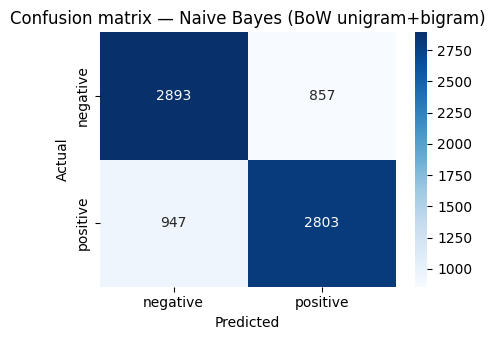


Naive Bayes (TF-IDF unigram+bigram)
              precision    recall  f1-score   support

    negative     0.7577    0.7773    0.7674      3750
    positive     0.7714    0.7515    0.7613      3750

    accuracy                         0.7644      7500
   macro avg     0.7646    0.7644    0.7644      7500
weighted avg     0.7646    0.7644    0.7644      7500



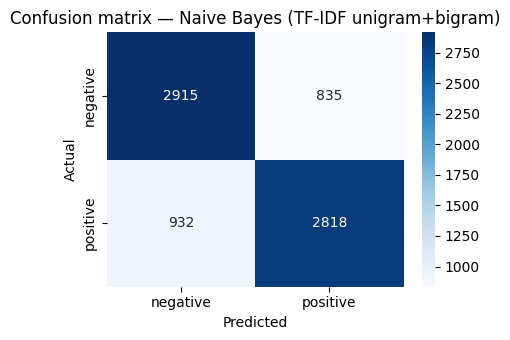

In [8]:
# Fit vectorizers only on training text to prevent leakage.
nb_results = {}
for feature_name, vectorizer in [
    ("BoW unigram+bigram", CountVectorizer(ngram_range=(1,2), min_df=2, max_features=150000)),
    ("TF-IDF unigram+bigram", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=150000, sublinear_tf=True)),
]:
    model = Pipeline([
        ("vectorizer", vectorizer),
        ("classifier", MultinomialNB(alpha=0.5))
    ])
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start
    pred = model.predict(X_test)
    name = "Naive Bayes (" + feature_name + ")"
    nb_results[feature_name] = model
    evaluate_model(name, y_test, pred, elapsed, feature_name)


## Cell 9 — Most discriminative features from TF-IDF Naive Bayes


In [9]:
# For binary MultinomialNB, log-count/log-probability differences indicate class association.
nb_tfidf = nb_results["TF-IDF unigram+bigram"]
vec = nb_tfidf.named_steps["vectorizer"]
clf = nb_tfidf.named_steps["classifier"]
feature_names = np.asarray(vec.get_feature_names_out())
log_prob = clf.feature_log_prob_
difference = log_prob[1] - log_prob[0]
top_positive = feature_names[np.argsort(difference)[-15:][::-1]]
top_negative = feature_names[np.argsort(difference)[:15]]
print("Top 15 features associated with POSITIVE sentiment:")
print(", ".join(top_positive))
print("\nTop 15 features associated with NEGATIVE sentiment:")
print(", ".join(top_negative))


Top 15 features associated with POSITIVE sentiment:
user happy, for following, the follow, thanks you, user okay, user thank, thank you, user goodnight, once you, hi there, user sweet, sweetheart, 100 followers, tgif, your welcome

Top 15 features associated with NEGATIVE sentiment:
so sad, headache, sad, why is, missing my, user ugh, not feeling, sad day, lost my, hurts, is missing, throat, not good, im sorry, miss my


## Cell 9bis — NOUVEAU : impact des mots de négation (étape 2 du TP)

On entraîne le même Naive Bayes (TF-IDF, unigrammes+bigrammes) deux fois : avec les négations conservées, puis supprimées (`not`, `no`, `never`, `n't`). On mesure aussi la précision sur le sous-ensemble des tweets de test qui contiennent une négation.


In [10]:
# Étude de l'impact des négations sur Naive Bayes (mêmes splits, mêmes hyperparamètres)
NEG_RE = re.compile(r"\b(not|no|never)\b|n't")

def has_negation(text):
    return bool(NEG_RE.search(text))

neg_mask_test = np.array([has_negation(t) for t in X_test])
print(f"Tweets de test contenant une négation : {neg_mask_test.sum()} / {len(X_test)} ({neg_mask_test.mean():.1%})")

rows = []
for mode, remove in [("négations conservées", False), ("négations supprimées", True)]:
    Xtr = train_df["text"].map(lambda t: clean_tweet(t, remove_negations=remove)).tolist()
    Xte = test_df["text"].map(lambda t: clean_tweet(t, remove_negations=remove)).tolist()
    for fname, vec in [
        ("BoW", CountVectorizer(ngram_range=(1,2), min_df=2, max_features=150000)),
        ("TF-IDF", TfidfVectorizer(ngram_range=(1,2), min_df=2, max_features=150000, sublinear_tf=True)),
    ]:
        m = Pipeline([("vectorizer", vec), ("classifier", MultinomialNB(alpha=0.5))])
        m.fit(Xtr, y_train)
        p = m.predict(Xte)
        rows.append({
            "Négations": mode, "Features": fname,
            "Accuracy": accuracy_score(y_test, p),
            "F1_macro": f1_score(y_test, p, average="macro"),
            "Acc. tweets AVEC négation": accuracy_score(y_test[neg_mask_test], p[neg_mask_test]),
            "Acc. tweets SANS négation": accuracy_score(y_test[~neg_mask_test], p[~neg_mask_test]),
        })
neg_study_df = pd.DataFrame(rows)
display(neg_study_df.round(4))
neg_study_df.to_csv("tp4_negation_study.csv", index=False)


Tweets de test contenant une négation : 1545 / 7500 (20.6%)


,Négations,Features,Accuracy,F1_macro,Acc. tweets AVEC négation,Acc. tweets SANS négation
0,négations conservées,BoW,0.7595,0.7594,0.7197,0.7698
1,négations conservées,TF-IDF,0.7644,0.7644,0.7230,0.7751
2,négations supprimées,BoW,0.7536,0.7536,0.6951,0.7688
3,négations supprimées,TF-IDF,0.7605,0.7605,0.6990,0.7765


## Cell 10 — RNN/LSTM tokenization and padding


Epoch 1/4
274/274 ━━━━━━━━━━━━━━━━━━━━ 13s 29ms/step - accuracy: 0.6973 - loss: 0.5712 - val_accuracy: 0.7721 - val_loss: 0.4801
Epoch 2/4
274/274 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8237 - loss: 0.4030 - val_accuracy: 0.7656 - val_loss: 0.4985
SimpleRNN: 15.2s au total pour 2 époque(s) (la 1re inclut l'initialisation GPU).

SimpleRNN
              precision    recall  f1-score   support

    negative     0.7635    0.7715    0.7675      3750
    positive     0.7691    0.7611    0.7650      3750

    accuracy                         0.7663      7500
   macro avg     0.7663    0.7663    0.7663      7500
weighted avg     0.7663    0.7663    0.7663      7500



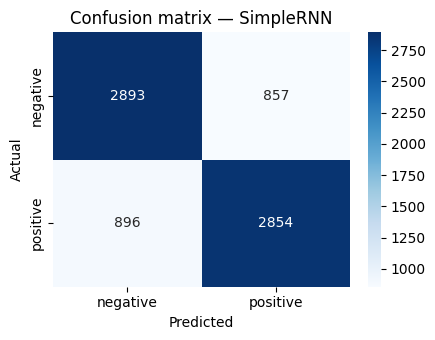

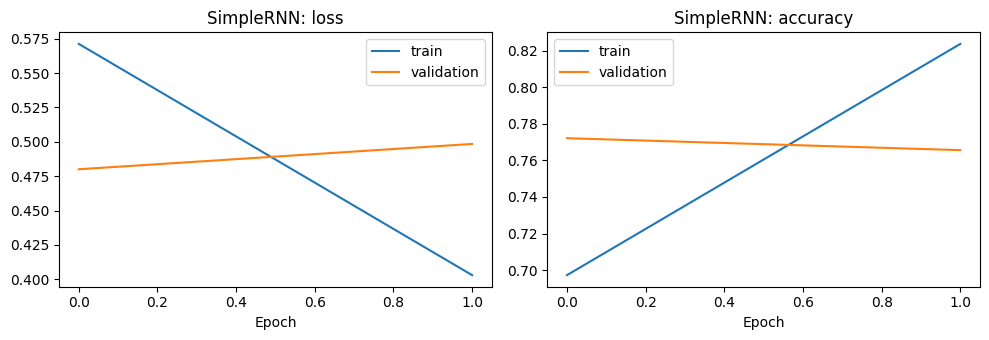

Epoch 1/4
274/274 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.7229 - loss: 0.5488 - val_accuracy: 0.7805 - val_loss: 0.4738
Epoch 2/4
274/274 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.8207 - loss: 0.4116 - val_accuracy: 0.7739 - val_loss: 0.4845
LSTM: 15.0s au total pour 2 époque(s) (la 1re inclut l'initialisation GPU).

LSTM
              precision    recall  f1-score   support

    negative     0.7751    0.7648    0.7699      3750
    positive     0.7679    0.7781    0.7730      3750

    accuracy                         0.7715      7500
   macro avg     0.7715    0.7715    0.7715      7500
weighted avg     0.7715    0.7715    0.7715      7500



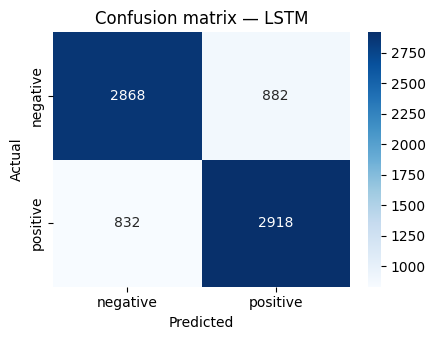

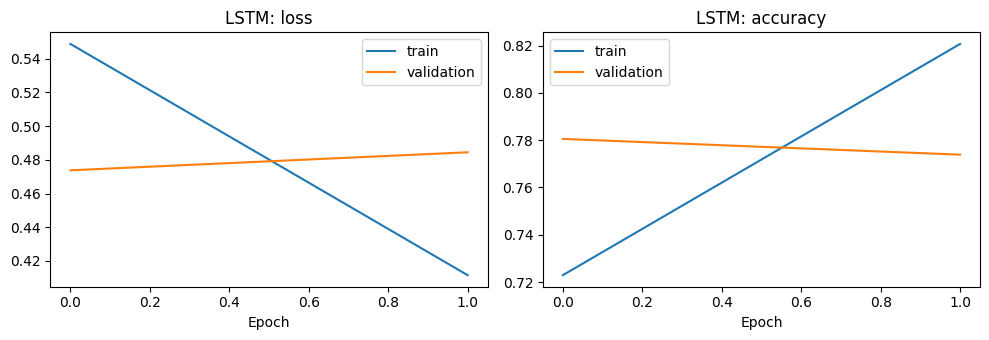

Epoch 1/4
274/274 ━━━━━━━━━━━━━━━━━━━━ 7s 18ms/step - accuracy: 0.7319 - loss: 0.5386 - val_accuracy: 0.7824 - val_loss: 0.4666
Epoch 2/4
274/274 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.8272 - loss: 0.3972 - val_accuracy: 0.7720 - val_loss: 0.4828
BiLSTM: 11.0s au total pour 2 époque(s) (la 1re inclut l'initialisation GPU).

BiLSTM
              precision    recall  f1-score   support

    negative     0.7651    0.7827    0.7738      3750
    positive     0.7776    0.7597    0.7685      3750

    accuracy                         0.7712      7500
   macro avg     0.7713    0.7712    0.7712      7500
weighted avg     0.7713    0.7712    0.7712      7500



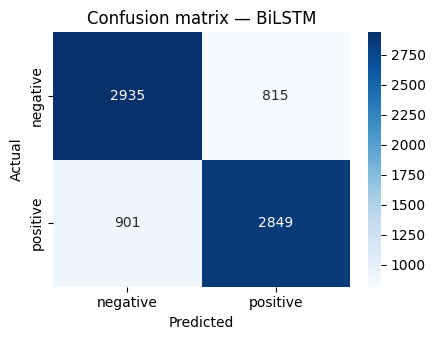

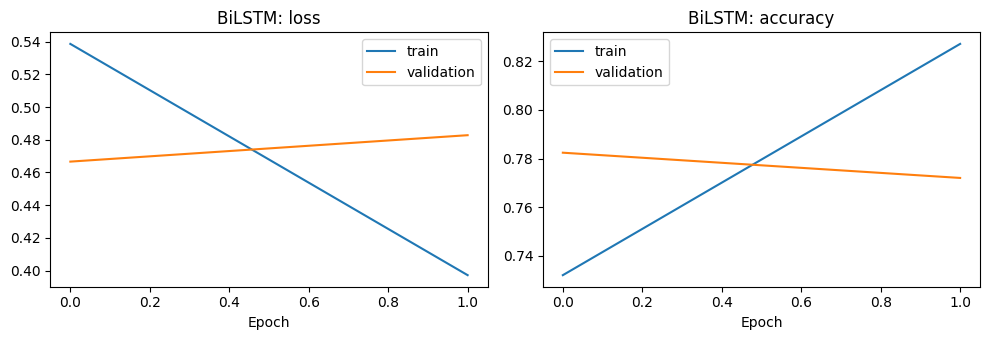

In [11]:
# Use Keras Tokenizer and same train/val/test split.
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models, callbacks

VOCAB_SIZE = 30000
MAX_LEN = 40
EMBED_DIM = 100
BATCH_SIZE = 128
EPOCHS_RNN = 4

keras_tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token="<OOV>", lower=True)
keras_tokenizer.fit_on_texts(X_train)  # training data only
seq_train = pad_sequences(keras_tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN, padding="post", truncating="post")
seq_val = pad_sequences(keras_tokenizer.texts_to_sequences(X_val), maxlen=MAX_LEN, padding="post", truncating="post")
seq_test = pad_sequences(keras_tokenizer.texts_to_sequences(X_test), maxlen=MAX_LEN, padding="post", truncating="post")

def build_recurrent(kind="rnn"):
    inp = layers.Input(shape=(MAX_LEN,), dtype="int32")
    x = layers.Embedding(VOCAB_SIZE, EMBED_DIM, mask_zero=True)(inp)
    x = layers.SpatialDropout1D(0.2)(x)
    if kind == "rnn":
        x = layers.SimpleRNN(64, dropout=0.2, recurrent_dropout=0.0)(x)
        name = "SimpleRNN"
    elif kind == "bilstm":
        x = layers.Bidirectional(layers.LSTM(64, dropout=0.2, recurrent_dropout=0.0))(x)
        name = "BiLSTM"
    else:
        x = layers.LSTM(64, dropout=0.2, recurrent_dropout=0.0)(x)
        name = "LSTM"
    x = layers.Dense(32, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation="sigmoid")(x)
    model = models.Model(inp, out, name=name)
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

histories = {}
recurrent_models = {}
for kind, name in [("rnn", "SimpleRNN"), ("lstm", "LSTM"), ("bilstm", "BiLSTM")]:
    model = build_recurrent(kind)
    stop_early = callbacks.EarlyStopping(monitor="val_loss", patience=1, restore_best_weights=True)
    start = time.time()
    history = model.fit(
        seq_train, y_train, validation_data=(seq_val, y_val),
        epochs=EPOCHS_RNN, batch_size=BATCH_SIZE, callbacks=[stop_early], verbose=1
    )
    elapsed = time.time() - start
    print(f"{name}: {elapsed:.1f}s au total pour {len(history.history['loss'])} époque(s) (la 1re inclut l'initialisation GPU).")
    probs = model.predict(seq_test, batch_size=BATCH_SIZE, verbose=0).ravel()
    pred = (probs >= 0.5).astype(int)
    histories[name] = history
    recurrent_models[name] = model
    evaluate_model(name, y_test, pred, elapsed, "Integer sequences + Embedding")

    # Plot training/validation loss and accuracy
    hist = history.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(hist["loss"], label="train")
    axes[0].plot(hist["val_loss"], label="validation")
    axes[0].set_title(f"{name}: loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(hist["accuracy"], label="train")
    axes[1].plot(hist["val_accuracy"], label="validation")
    axes[1].set_title(f"{name}: accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


## Cell 11 — DistilBERT fine-tuning (PyTorch)

PyTorch est utilisé car le chargement de checkpoints TensorFlow échouait sur Colab. Entraînement sur **tout** le jeu d'entraînement (35 000 tweets), même jeu de test que les autres modèles, poids de la meilleure époque restaurés.


DistilBERT device: cuda


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch 1/2 — train loss: 0.4509 — validation loss: 0.4082
Epoch 2/2 — train loss: 0.3353 — validation loss: 0.4358
Poids restaurés : époque 1 (val_loss = 0.4082)


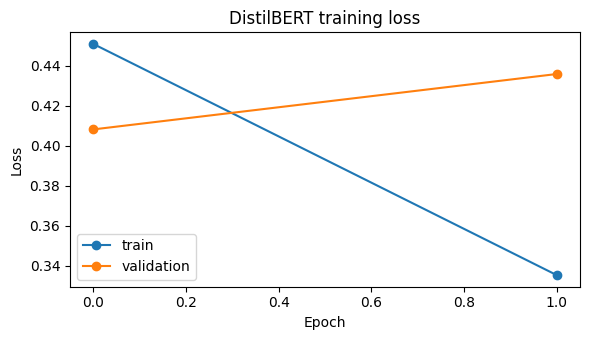


DistilBERT
              precision    recall  f1-score   support

    negative     0.8216    0.7997    0.8105      3750
    positive     0.8049    0.8264    0.8155      3750

    accuracy                         0.8131      7500
   macro avg     0.8133    0.8131    0.8130      7500
weighted avg     0.8133    0.8131    0.8130      7500



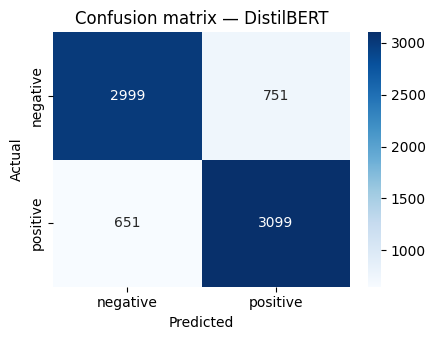

{'Model': 'DistilBERT',
 'Representation': 'WordPiece + pretrained attention (train=35000, test=7500)',
 'Accuracy': 0.8130666666666667,
 'Precision_macro': 0.8132894502757517,
 'Recall_macro': 0.8130666666666666,
 'F1_macro': 0.8130334281650071,
 'Training_seconds': 505.6998212337494}

In [12]:
# DistilBERT fine-tuning with PyTorch (avoids TensorFlow checkpoint conversion issues).
# Uses the same held-out test split as the other models.
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from torch.optim import AdamW

MODEL_NAME = "distilbert/distilbert-base-uncased"
BERT_MAX_LEN = 64   # les tweets font <= 140 caractères : 64 tokens WordPiece suffisent
BERT_TRAIN_LIMIT = None   # None = tout le train (35 000), comme les autres modèles
BERT_VAL_LIMIT = None     # None = tout le jeu de validation
BERT_TEST_LIMIT = None   # keep None for the full shared test set
BERT_EPOCHS = 2
BERT_BATCH_SIZE = 16
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("DistilBERT device:", device)

bert_train = train_df.copy() if BERT_TRAIN_LIMIT is None else train_df.sample(n=min(BERT_TRAIN_LIMIT, len(train_df)), random_state=SEED).copy()
bert_val = val_df.copy() if BERT_VAL_LIMIT is None else val_df.sample(n=min(BERT_VAL_LIMIT, len(val_df)), random_state=SEED).copy()
bert_test = test_df.copy() if BERT_TEST_LIMIT is None else test_df.sample(n=min(BERT_TEST_LIMIT, len(test_df)), random_state=SEED).copy()

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
bert_model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2).to(device)

class SentimentDataset(Dataset):
    def __init__(self, texts, labels=None):
        self.encodings = bert_tokenizer(
            list(texts), truncation=True, padding="max_length",
            max_length=BERT_MAX_LEN, return_tensors="pt"
        )
        self.labels = None if labels is None else torch.tensor(np.asarray(labels), dtype=torch.long)
    def __len__(self):
        return self.encodings["input_ids"].shape[0]
    def __getitem__(self, idx):
        item = {key: value[idx] for key, value in self.encodings.items()}
        if self.labels is not None:
            item["labels"] = self.labels[idx]
        return item

bert_train_ds = SentimentDataset(bert_train["clean_text"], bert_train["label"])
bert_val_ds = SentimentDataset(bert_val["clean_text"], bert_val["label"])
bert_test_ds = SentimentDataset(bert_test["clean_text"], bert_test["label"])

bert_train_loader = DataLoader(bert_train_ds, batch_size=BERT_BATCH_SIZE, shuffle=True)
bert_val_loader = DataLoader(bert_val_ds, batch_size=BERT_BATCH_SIZE, shuffle=False)
bert_test_loader = DataLoader(bert_test_ds, batch_size=BERT_BATCH_SIZE, shuffle=False)

optimizer = AdamW(bert_model.parameters(), lr=2e-5)
bert_start = time.time()
bert_history = {"train_loss": [], "val_loss": []}
best_val, best_state, best_epoch = float("inf"), None, 0

for epoch in range(BERT_EPOCHS):
    bert_model.train()
    total_train_loss = 0.0
    for batch in bert_train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        optimizer.zero_grad()
        output = bert_model(**batch)
        loss = output.loss
        loss.backward()
        torch.nn.utils.clip_grad_norm_(bert_model.parameters(), 1.0)
        optimizer.step()
        total_train_loss += loss.item()
    mean_train_loss = total_train_loss / max(1, len(bert_train_loader))

    bert_model.eval()
    total_val_loss = 0.0
    with torch.no_grad():
        for batch in bert_val_loader:
            batch = {k: v.to(device) for k, v in batch.items()}
            output = bert_model(**batch)
            total_val_loss += output.loss.item()
    mean_val_loss = total_val_loss / max(1, len(bert_val_loader))
    bert_history["train_loss"].append(mean_train_loss)
    bert_history["val_loss"].append(mean_val_loss)
    print(f"Epoch {epoch+1}/{BERT_EPOCHS} — train loss: {mean_train_loss:.4f} — validation loss: {mean_val_loss:.4f}")
    if mean_val_loss < best_val:   # on garde les poids de la meilleure époque
        best_val, best_epoch = mean_val_loss, epoch + 1
        best_state = {k: v.detach().cpu().clone() for k, v in bert_model.state_dict().items()}

bert_elapsed = time.time() - bert_start
bert_model.load_state_dict(best_state)
print(f"Poids restaurés : époque {best_epoch} (val_loss = {best_val:.4f})")
bert_model.eval()
bert_predictions = []
with torch.no_grad():
    for batch in bert_test_loader:
        batch = {k: v.to(device) for k, v in batch.items() if k != "labels"}
        logits = bert_model(**batch).logits
        bert_predictions.extend(torch.argmax(logits, dim=1).cpu().numpy().tolist())
bert_pred = np.asarray(bert_predictions)

plt.figure(figsize=(6, 3.5))
plt.plot(bert_history["train_loss"], marker="o", label="train")
plt.plot(bert_history["val_loss"], marker="o", label="validation")
plt.title("DistilBERT training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

evaluate_model(
    "DistilBERT", bert_test["label"].to_numpy(), bert_pred,
    bert_elapsed,
    f"WordPiece + pretrained attention (train={len(bert_train)}, test={len(bert_test)})"
)


## Cell 12 — Results table


In [13]:
results_df = pd.DataFrame(results)
display(results_df.sort_values("F1_macro", ascending=False).reset_index(drop=True))
results_df.to_csv("tp4_model_comparison.csv", index=False)
print("Saved: tp4_model_comparison.csv")


,Model,Representation,Accuracy,Precision_macro,Recall_macro,F1_macro,Training_seconds
0,DistilBERT,"WordPiece + pretrained attention (train=35000,...",0.813067,0.813289,0.813067,0.813033,505.699821
1,LSTM,Integer sequences + Embedding,0.771467,0.771515,0.771467,0.771457,15.001431
2,BiLSTM,Integer sequences + Embedding,0.771200,0.771343,0.771200,0.771170,10.963900
3,SimpleRNN,Integer sequences + Embedding,0.766267,0.766295,0.766267,0.766260,15.154773
4,Naive Bayes (TF-IDF unigram+bigram),TF-IDF unigram+bigram,0.764400,0.764577,0.764400,0.764361,1.319091
5,Naive Bayes (BoW unigram+bigram),BoW unigram+bigram,0.759467,0.759616,0.759467,0.759432,1.679640


Saved: tp4_model_comparison.csv


## Cell 12bis — NOUVEAU : tableau au format du TP


In [14]:
tp_table = results_df.rename(columns={
    "Model": "Modèle", "Representation": "Représentation", "Precision_macro": "Précision",
    "Recall_macro": "Rappel", "F1_macro": "F1-Score", "Training_seconds": "Temps (s)"
})[["Modèle", "Représentation", "Accuracy", "Précision", "Rappel", "F1-Score", "Temps (s)"]]
display(tp_table.round(4))
tp_table.to_csv("tp4_tableau_recapitulatif.csv", index=False)


,Modèle,Représentation,Accuracy,Précision,Rappel,F1-Score,Temps (s)
0,Naive Bayes (BoW unigram+bigram),BoW unigram+bigram,0.7595,0.7596,0.7595,0.7594,1.6796
1,Naive Bayes (TF-IDF unigram+bigram),TF-IDF unigram+bigram,0.7644,0.7646,0.7644,0.7644,1.3191
2,SimpleRNN,Integer sequences + Embedding,0.7663,0.7663,0.7663,0.7663,15.1548
3,LSTM,Integer sequences + Embedding,0.7715,0.7715,0.7715,0.7715,15.0014
4,BiLSTM,Integer sequences + Embedding,0.7712,0.7713,0.7712,0.7712,10.9639
5,DistilBERT,"WordPiece + pretrained attention (train=35000,...",0.8131,0.8133,0.8131,0.8130,505.6998


## Cell 13 — Five qualitative challenge sentences


In [15]:
# These are manually chosen challenge examples, not ground truth from Sentiment140.
challenge_sentences = [
    "I do not dislike this phone; it is actually pretty good.",
    "The food was not bad, but the service was absolutely awful.",
    "I thought the update would not be useless, and it was genuinely helpful.",
    "Wonderful, another app crash right before my deadline. Just perfect.",
    "I love how this supposedly amazing product stopped working after one day."
]
challenge_clean = [clean_tweet(s) for s in challenge_sentences]

# Naive Bayes, SimpleRNN, and LSTM predictions.
nb_challenge_pred = nb_tfidf.predict(challenge_clean)
challenge_seq = pad_sequences(
    keras_tokenizer.texts_to_sequences(challenge_clean),
    maxlen=MAX_LEN, padding="post", truncating="post"
)
rnn_challenge = (recurrent_models["SimpleRNN"].predict(challenge_seq, verbose=0).ravel() >= 0.5).astype(int)
lstm_challenge = (recurrent_models["LSTM"].predict(challenge_seq, verbose=0).ravel() >= 0.5).astype(int)
bilstm_challenge = (recurrent_models["BiLSTM"].predict(challenge_seq, verbose=0).ravel() >= 0.5).astype(int)

# DistilBERT predictions with PyTorch.
bert_model.eval()
challenge_enc = bert_tokenizer(
    challenge_clean, truncation=True, padding="max_length",
    max_length=BERT_MAX_LEN, return_tensors="pt"
)
challenge_enc = {k: v.to(device) for k, v in challenge_enc.items()}
with torch.no_grad():
    bert_challenge = torch.argmax(bert_model(**challenge_enc).logits, dim=1).cpu().numpy()

challenge_expected = ["Positive", "Mixte (négatif dominant)", "Positive", "Negative (sarcasme)", "Negative (sarcasme)"]
challenge_df = pd.DataFrame({
    "Sentence": challenge_sentences,
    "Attendu": challenge_expected,
    "Naive Bayes": np.where(nb_challenge_pred == 1, "Positive", "Negative"),
    "SimpleRNN": np.where(rnn_challenge == 1, "Positive", "Negative"),
    "LSTM": np.where(lstm_challenge == 1, "Positive", "Negative"),
    "BiLSTM": np.where(bilstm_challenge == 1, "Positive", "Negative"),
    "DistilBERT": np.where(bert_challenge == 1, "Positive", "Negative"),
})
display(challenge_df)
challenge_df.to_csv("tp4_challenge_predictions.csv", index=False)


,Sentence,Attendu,Naive Bayes,SimpleRNN,LSTM,BiLSTM,DistilBERT
0,I do not dislike this phone; it is actually pr...,Positive,Negative,Negative,Negative,Negative,Positive
1,"The food was not bad, but the service was abso...",Mixte (négatif dominant),Negative,Negative,Negative,Negative,Negative
2,"I thought the update would not be useless, and...",Positive,Negative,Negative,Negative,Negative,Positive
3,"Wonderful, another app crash right before my d...",Negative (sarcasme),Negative,Positive,Positive,Positive,Positive
4,I love how this supposedly amazing product sto...,Negative (sarcasme),Positive,Positive,Positive,Positive,Negative


## Cell 14 — Error analysis on test set


In [16]:
# Review false positives and false negatives for each model.
def error_examples(model_name, texts, y_true, y_pred, n=10):
    errors = pd.DataFrame({
        "text": list(texts), "true": np.asarray(y_true), "predicted": np.asarray(y_pred)
    })
    errors = errors[errors["true"] != errors["predicted"]].copy()
    errors["error_type"] = np.where(
        (errors["true"] == 0) & (errors["predicted"] == 1),
        "False positive", "False negative"
    )
    print(f"{model_name}: {len(errors)} errors out of {len(errors) + (np.asarray(y_true) == np.asarray(y_pred)).sum()} examples")
    display(errors.groupby("error_type", group_keys=False).head(max(1, n//2)))
    return errors

for name, pred in predictions.items():
    if len(pred) == len(y_test):
        errs = error_examples(name, X_test, y_test, pred, n=10)
        errs.to_csv(f"errors_{re.sub(r'[^A-Za-z0-9]+','_',name)}.csv", index=False)


Naive Bayes (BoW unigram+bigram): 1804 errors out of 7500 examples


,text,true,predicted,error_type
1,on my way to six flags with kaylee,1,0,False negative
4,yoga haircut beach love summers at the shore h...,1,0,False negative
6,going for a japanese green tea and my web host...,0,1,False positive
15,wishes she could see acey and steve play toget...,0,1,False positive
19,meeting friend at athens airport today that i ...,1,0,False negative
21,user omg sorry i love you sooooo much you know...,1,0,False negative
24,and here's my website i was so proud of yester...,0,1,False positive
31,the new hawthorne heights stuff sounds so weir...,0,1,False positive
33,user i'd never noticed,1,0,False negative
38,user when will you be back i miss you,0,1,False positive


Naive Bayes (TF-IDF unigram+bigram): 1767 errors out of 7500 examples


,text,true,predicted,error_type
1,on my way to six flags with kaylee,1,0,False negative
4,yoga haircut beach love summers at the shore h...,1,0,False negative
6,going for a japanese green tea and my web host...,0,1,False positive
15,wishes she could see acey and steve play toget...,0,1,False positive
19,meeting friend at athens airport today that i ...,1,0,False negative
21,user omg sorry i love you sooooo much you know...,1,0,False negative
24,and here's my website i was so proud of yester...,0,1,False positive
31,the new hawthorne heights stuff sounds so weir...,0,1,False positive
33,user i'd never noticed,1,0,False negative
41,blaming riots on foreign zionist media death t...,0,1,False positive


SimpleRNN: 1753 errors out of 7500 examples


,text,true,predicted,error_type
2,at work reading my mail 65 new mails,0,1,False positive
6,going for a japanese green tea and my web host...,0,1,False positive
10,i'm really glad my sisters would not go to the...,0,1,False positive
14,cant w8 2 watch the final of the apprentice 2n...,1,0,False negative
15,wishes she could see acey and steve play toget...,0,1,False positive
19,meeting friend at athens airport today that i ...,1,0,False negative
21,user omg sorry i love you sooooo much you know...,1,0,False negative
24,and here's my website i was so proud of yester...,0,1,False positive
44,is cringing when the amount of updates inevita...,1,0,False negative
46,just walked haley home on my way back now,1,0,False negative


... (2 outputs left out)

BiLSTM: 1716 errors out of 7500 examples


,text,true,predicted,error_type
1,on my way to six flags with kaylee,1,0,False negative
2,at work reading my mail 65 new mails,0,1,False positive
6,going for a japanese green tea and my web host...,0,1,False positive
10,i'm really glad my sisters would not go to the...,0,1,False positive
14,cant w8 2 watch the final of the apprentice 2n...,1,0,False negative
15,wishes she could see acey and steve play toget...,0,1,False positive
19,meeting friend at athens airport today that i ...,1,0,False negative
21,user omg sorry i love you sooooo much you know...,1,0,False negative
24,and here's my website i was so proud of yester...,0,1,False positive
33,user i'd never noticed,1,0,False negative


DistilBERT: 1402 errors out of 7500 examples


,text,true,predicted,error_type
16,user congratulations even me couldnt do it bet...,1,0,False negative
21,user omg sorry i love you sooooo much you know...,1,0,False negative
24,and here's my website i was so proud of yester...,0,1,False positive
29,hope my granma will get well soon love u wan,0,1,False positive
50,user lechuga did u ever get our list my letter...,1,0,False negative
60,user that jason mraz link is not working and i...,0,1,False positive
91,user hey girl doin' ok here what's up with the...,0,1,False positive
92,user it will be a fun day though i am so sorry...,1,0,False negative
93,going to the city tonight i really want to see...,1,0,False negative
94,morning my twitts 2day is a hard day for me bu...,0,1,False positive


## Cell 14bis — NOUVEAU : erreurs sur les tweets contenant une négation


In [17]:
# Précision de chaque modèle sur les tweets AVEC / SANS négation (même jeu de test)
rows = []
for name, pred in predictions.items():
    if len(pred) != len(y_test):
        continue
    rows.append({
        "Modèle": name,
        "Acc. AVEC négation": accuracy_score(y_test[neg_mask_test], pred[neg_mask_test]),
        "Acc. SANS négation": accuracy_score(y_test[~neg_mask_test], pred[~neg_mask_test]),
    })
neg_acc_df = pd.DataFrame(rows)
neg_acc_df["Écart"] = neg_acc_df["Acc. SANS négation"] - neg_acc_df["Acc. AVEC négation"]
display(neg_acc_df.round(4))
neg_acc_df.to_csv("tp4_negation_accuracy_by_model.csv", index=False)

# Exemples de tweets avec négation mal classés par Naive Bayes mais bien classés par DistilBERT
nb_name = "Naive Bayes (TF-IDF unigram+bigram)"
fixed = np.where(neg_mask_test & (predictions[nb_name] != y_test) & (predictions["DistilBERT"] == y_test))[0]
print(f"\nTweets avec négation : erreur NB corrigée par DistilBERT = {len(fixed)}")
for i in fixed[:8]:
    print(f"- vrai={y_test[i]}  NB={predictions[nb_name][i]}  BERT={predictions['DistilBERT'][i]} | {X_test[i]}")


,Modèle,Acc. AVEC négation,Acc. SANS négation,Écart
0,Naive Bayes (BoW unigram+bigram),0.7197,0.7698,0.0500
1,Naive Bayes (TF-IDF unigram+bigram),0.7230,0.7751,0.0522
2,SimpleRNN,0.7184,0.7787,0.0602
3,LSTM,0.7210,0.7846,0.0635
4,BiLSTM,0.7172,0.7852,0.0681
5,DistilBERT,0.7754,0.8228,0.0474



Tweets avec négation : erreur NB corrigée par DistilBERT = 217
- vrai=1  NB=0  BERT=1 | meeting friend at athens airport today that i have not seen for ages and she is bringing real nyc bagels too
- vrai=1  NB=0  BERT=1 | user i'd never noticed
- vrai=0  NB=1  BERT=0 | blaming riots on foreign zionist media death to us uk israel yells crowd i don't hear sweden khamenei iranelection
- vrai=0  NB=1  BERT=0 | user yeah didn't make it to posscon heard it was pretty good
- vrai=1  NB=0  BERT=1 | user i always insist on going through ord never been a problem but then i'm so sedated to fly i don't really care
- vrai=0  NB=1  BERT=0 | user being recognized in public yet michael poor rob the boy can't even go out it cannes enjoy your tea
- vrai=1  NB=0  BERT=1 | user no one even mentioned that to me im not the only one who messed up the date
- vrai=0  NB=1  BERT=0 | rockband isn't as fun when you're playing alone


## Cell 15 — Save models and output artifacts


In [18]:
import zipfile
recurrent_models["SimpleRNN"].save("simple_rnn.keras")
recurrent_models["LSTM"].save("lstm.keras")
recurrent_models["BiLSTM"].save("bilstm.keras")
nb_tfidf_path = "naive_bayes_tfidf.joblib"
import joblib
joblib.dump(nb_tfidf, nb_tfidf_path)
bert_model.save_pretrained("distilbert_sentiment140")
bert_tokenizer.save_pretrained("distilbert_sentiment140")
with zipfile.ZipFile("tp4_models_and_results.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in [
        "simple_rnn.keras", "lstm.keras", "bilstm.keras", nb_tfidf_path,
        "tp4_negation_study.csv", "tp4_negation_accuracy_by_model.csv", "tp4_tableau_recapitulatif.csv",
        "tp4_model_comparison.csv", "tp4_challenge_predictions.csv"
    ]:
        if os.path.exists(f):
            z.write(f)
    if os.path.isdir("distilbert_sentiment140"):
        for root, dirs, files_ in os.walk("distilbert_sentiment140"):
            for f in files_:
                full = os.path.join(root, f)
                z.write(full, os.path.relpath(full, "."))
print("Saved model files and tp4_models_and_results.zip")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model files and tp4_models_and_results.zip


## Cell 16 — Download results (uncomment if desired)


In [19]:
# from google.colab import files
# files.download("tp4_model_comparison.csv")
# files.download("tp4_challenge_predictions.csv")
# files.download("tp4_models_and_results.zip")


## Cell 17 — Final sanity checks


In [20]:
print("Train/validation/test sizes:", len(train_df), len(val_df), len(test_df))
print("Comparison rows (NB has two feature variants):", len(results_df))
print("Check all measured metrics are between 0 and 1:")
display(results_df[["Model", "Accuracy", "Precision_macro", "Recall_macro", "F1_macro"]])


Train/validation/test sizes: 35000 7500 7500
Comparison rows (NB has two feature variants): 6
Check all measured metrics are between 0 and 1:


,Model,Accuracy,Precision_macro,Recall_macro,F1_macro
0,Naive Bayes (BoW unigram+bigram),0.759467,0.759616,0.759467,0.759432
1,Naive Bayes (TF-IDF unigram+bigram),0.764400,0.764577,0.764400,0.764361
2,SimpleRNN,0.766267,0.766295,0.766267,0.766260
3,LSTM,0.771467,0.771515,0.771467,0.771457
4,BiLSTM,0.771200,0.771343,0.771200,0.771170
5,DistilBERT,0.813067,0.813289,0.813067,0.813033
